# Kaggle · finish in one background run (distillation + benchmark + impact)
Runs notebooks **02** and **03** back to back on a free Kaggle GPU, using the checkpoints trained on Colab.

**Before running**
1. Upload `kaggle_upload.zip` (from notebook 00) as a Kaggle dataset, then attach it here with
   **Add Input → Datasets → Your Datasets**.
2. **Settings → Accelerator → GPU T4 x2** (or P100) and **Internet → on** (needs a phone-verified Kaggle account).
3. Click **Save Version → Save & Run All (Commit)**. It runs on Kaggle's servers, so **you can close
   the laptop**. With `LITE = True` expect about 2 hours.
4. When it finishes, open the version → **Output** → download `fastdiff_outputs.zip`.

### Setup
Works on **Google Colab** (saves to `MyDrive/fastdiff-med/`) and on **Kaggle** (saves to
`/kaggle/working/fastdiff-med/` and picks up uploaded checkpoints from `/kaggle/input/`). It clones or
updates the repo and installs dependencies. Training and distillation resume from their last
checkpoint, so after a disconnect you only rerun this notebook.

* `QUICK = True`: ~5-minute smoke test with tiny settings (outputs go to a separate `quick/` folder).
* `LITE = True`: about half the GPU time (fewer FID samples, shorter distillation rounds). The results
  are still valid, just a bit less precise.

*Colab: Runtime → Change runtime type → **T4 GPU**. Kaggle: Settings → Accelerator → **GPU T4**, Internet **on**.*

In [1]:
import os, sys, glob, shutil
QUICK = False   # True = tiny smoke-test settings (~5 min)
LITE = True     # True = about half the GPU time (recommended if GPU time is limited)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_KAGGLE = os.path.exists('/kaggle/working')
IN_COLAB = IN_COLAB and not IN_KAGGLE


if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE, CODE = '/content/drive/MyDrive/fastdiff-med', '/content/fastdiff-med'
elif IN_KAGGLE:
    BASE, CODE = '/kaggle/working/fastdiff-med', '/kaggle/working/fastdiff-med-code'
else:  # local Jupyter, started from the repo or its notebooks/ folder
    CODE = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
    BASE = os.path.join(CODE, 'workdir')

if IN_COLAB or IN_KAGGLE:
    if not os.path.exists(CODE):
        !git clone -q https://github.com/shreyu20sharma/fastdiff-med.git {CODE}
    %cd {CODE}
    !git pull -q
    !pip install -q -r requirements.txt
else:
    %cd {CODE}
if CODE not in sys.path:
    sys.path.insert(0, CODE)

ROOT = BASE + ('/quick' if QUICK else '')
CKPT, RESULTS, DOCS = f'{ROOT}/checkpoints', f'{ROOT}/results', f'{ROOT}/docs'
os.environ['MEDMNIST_ROOT'] = f'{BASE}/data'  # dataset cache (~20 MB)
for d in (CKPT, RESULTS, DOCS, os.environ['MEDMNIST_ROOT']):
    os.makedirs(d, exist_ok=True)

if IN_KAGGLE:  # copy checkpoints from an uploaded Kaggle dataset, keeping the A/ B/ D/ layout
    import zipfile
    for zf in glob.glob('/kaggle/input/**/*.zip', recursive=True):  # in case Kaggle kept the zip
        zipfile.ZipFile(zf).extractall('/kaggle/working/_upload')
    for f in glob.glob('/kaggle/input/**/*', recursive=True) + glob.glob('/kaggle/working/_upload/**/*', recursive=True):
        rel = f.split('checkpoints/', 1)[-1] if 'checkpoints/' in f else None
        if rel and os.path.isfile(f) and not os.path.exists(f'{CKPT}/{rel}'):
            os.makedirs(os.path.dirname(f'{CKPT}/{rel}'), exist_ok=True)
            shutil.copy(f, f'{CKPT}/{rel}')
    print('checkpoints:', sorted(glob.glob(f'{CKPT}/**/*.pt', recursive=True)))

import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (no GPU: only the light cells will work)')
print('Saving to', ROOT)

/kaggle/working/fastdiff-med-code
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
checkpoints: ['/kaggle/working/fastdiff-med/checkpoints/A/ema.pt', '/kaggle/working/fastdiff-med/checkpoints/B/ema.pt', '/kaggle/working/fastdiff-med/checkpoints/C/ema.pt', '/kaggle/working/fastdiff-med/checkpoints/D/ema.pt']
GPU: Tesla T4
Saving to /kaggle/working/fastdiff-med


In [2]:
# Keep C only if it finished all 12,000 steps; a half-trained C would make the comparison unfair
c = f'{CKPT}/C/ema.pt'
if os.path.exists(c):
    steps = torch.load(c, map_location='cpu', weights_only=False)['config'].get('train_steps', 0)
    if steps < 12000:
        shutil.rmtree(f'{CKPT}/C')
        print(f'C removed: only trained {steps} of 12000 steps')
    else:
        print('C is fully trained, keeping it')


C removed: only trained 10000 of 12000 steps


In [3]:
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
def show(path, width=None):
    if os.path.exists(path):
        display(Image(filename=path, width=width))
    else:
        print('missing:', path)

# Part 1 · Progressive distillation (notebook 02)

In [4]:
ITERS = 50 if QUICK else (1500 if LITE else 4000)   # iterations per distillation round
BATCH = 32 if QUICK else 128
END_STEPS = 4                           # set to 8 if short on time
!python -m src.distill --teacher {CKPT}/D/ema.pt --ckpt_dir {CKPT} --start_steps 32 --end_steps {END_STEPS} --iters_per_round {ITERS} --batch {BATCH} --log_every 500

100%|██████████████████████████████████████| 19.7M/19.7M [00:04<00:00, 4.88MB/s]
[round 1] teacher 32 steps (CFG w=2.0) -> student 16 steps
[round 1] it   500/1500 loss 0.00040 1.4 it/s
[round 1] it  1000/1500 loss 0.00029 1.4 it/s
[round 1] it  1500/1500 loss 0.00026 1.4 it/s
[round 1] saved /kaggle/working/fastdiff-med/checkpoints/distill/student_16step.pt
[round 2] teacher 16 steps (CFG w=1.0) -> student 8 steps
[round 2] it   500/1500 loss 0.00022 2.0 it/s
[round 2] it  1000/1500 loss 0.00015 2.0 it/s
[round 2] it  1500/1500 loss 0.00014 2.0 it/s
[round 2] saved /kaggle/working/fastdiff-med/checkpoints/distill/student_8step.pt
[round 3] teacher 8 steps (CFG w=1.0) -> student 4 steps
[round 3] it   500/1500 loss 0.00018 2.0 it/s
[round 3] it  1000/1500 loss 0.00012 2.0 it/s
[round 3] it  1500/1500 loss 0.00010 2.0 it/s
[round 3] saved /kaggle/working/fastdiff-med/checkpoints/distill/student_4step.pt


## Visual check per round
The same seed and classes (one row per class) for the 20-step teacher with guidance and each
student. The student images should stay sharp and class-consistent as steps drop.

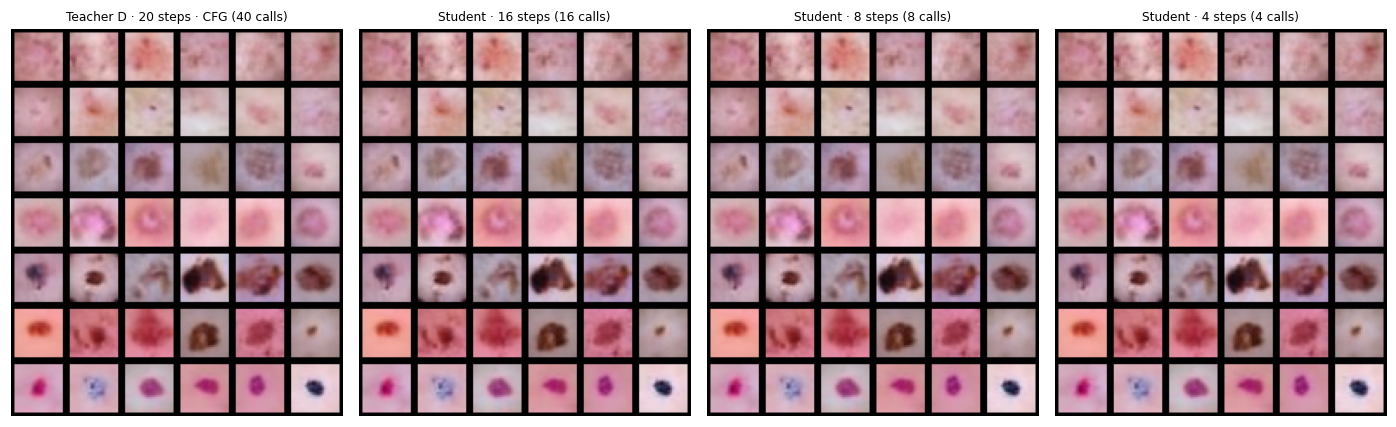

In [5]:
import glob, matplotlib.pyplot as plt
from src.utils import load_model
from src.sampling import sample_images
from src.evaluate import grid_labels, save_grid

def grid_img(x):
    return ((x + 1) / 2).clamp(0, 1).view(7, 6, 3, 32, 32).permute(0, 3, 1, 4, 2).reshape(7 * 32, 6 * 32, 3).numpy()

panels = []
m, dif, _ = load_model(f'{CKPT}/D/ema.pt')
panels.append(('Teacher D · 20 steps · CFG (40 calls)', sample_images(m, dif, grid_labels(6), 'ddim', 20, 2.0, seed=0)))
students = sorted(glob.glob(f'{CKPT}/distill/student_*step.pt'), key=lambda p: -int(p.split('_')[-1][:-7]))
for p in students:
    m, dif, cfg = load_model(p)
    panels.append((f"Student · {cfg['steps']} steps ({cfg['steps']} calls)",
                   sample_images(m, dif, grid_labels(6), 'ddim', cfg['steps'], 1.0, seed=0)))
fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 4), dpi=110)
for ax, (t, x) in zip(np.atleast_1d(axes), panels):
    ax.imshow(grid_img(x)); ax.set_title(t, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

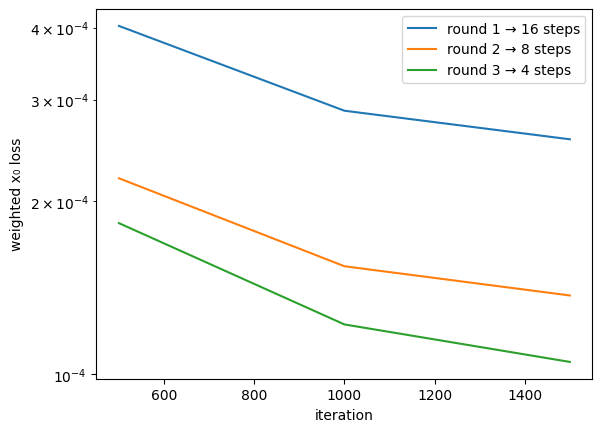

In [6]:
# Distillation loss per round
import pandas as pd
log = pd.read_csv(f'{CKPT}/distill/log.csv')
for (r, s), g in log.groupby(['round', 'student_steps']):
    plt.plot(g['iter'], g['loss'], label=f'round {r} → {s} steps')
plt.yscale('log'); plt.xlabel('iteration'); plt.ylabel('weighted x₀ loss'); plt.legend(); plt.show()

# Part 2 · Benchmark and impact (notebook 03)

## 1. Judge classifier
A ResNet-18 trained on real DermaMNIST with class-weighted loss. It scores whether a generated
"melanoma" actually looks like a melanoma. Its own test accuracy is reported so sample accuracy can be
read relative to it.

In [7]:
JUDGE_EPOCHS = 2 if QUICK else (25 if LITE else 40)
if not os.path.exists(f'{CKPT}/judge.pt'):
    !python -m src.judge_classifier --ckpt_dir {CKPT} --results_dir {RESULTS} --epochs {JUDGE_EPOCHS}
else:
    print('judge.pt exists, skipping')

  epoch   5/25 val bal-acc 0.369 (best 0.369)
  epoch  10/25 val bal-acc 0.545 (best 0.548)
  epoch  15/25 val bal-acc 0.529 (best 0.548)
  epoch  20/25 val bal-acc 0.533 (best 0.550)
  epoch  25/25 val bal-acc 0.547 (best 0.560)
judge test: acc 0.742  balanced acc 0.605  macro-F1 0.579  (58s)


## 2. Quality vs. speed benchmark
Every trained run is evaluated with DDIM (trailing timesteps) at 5, 10, 20 and 50 steps, the
baseline is also evaluated with the original 1000-step DDPM, and every distilled student is evaluated
at its own step count. FID uses 5,000 samples per configuration; the 1000-step baseline uses 1,000
(it is about 50× slower).

In [8]:
if QUICK:
    !python -m src.evaluate --ckpt_dir {CKPT} --results_dir {RESULTS} --docs_dir {DOCS} --n_fid 200 --n_fid_ddpm 20 --steps 5 20
elif LITE:
    !python -m src.evaluate --ckpt_dir {CKPT} --results_dir {RESULTS} --docs_dir {DOCS} --n_fid 2000 --n_fid_ddpm 500 --steps 5 10 20
else:
    !python -m src.evaluate --ckpt_dir {CKPT} --results_dir {RESULTS} --docs_dir {DOCS} --n_fid 5000 --n_fid_ddpm 1000 --steps 5 10 20 50

  (skipping run C: /kaggle/working/fastdiff-med/checkpoints/C/ema.pt not found)
Evaluating 13 configurations on cuda
[A-ddpm-1000] generating 500 samples ...
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
[A-ddpm-1000] FID 16.69  class-acc 0.783  1598.00 ms/img  single 16274 ms  (metrics 15s)
[A-ddim-5] generating 2000 samples ...
[A-ddim-5] FID 143.60  class-acc 0.723  7.99 ms/img  single 85 ms  (metrics 21s)
[A-ddim-10] generating 2000 samples ...
[A-ddim-10] FID 93.46  class-acc 0.717  16.17 ms/img  single 167 ms  (metrics 22s)
[A-ddim-20] generating 2000 samples ...
[A-ddim-20] FID 53.79  class-acc 0.729  31.99 ms/img  single 350 ms  (metrics 21s)
[B-ddim-5] generating 2000 samples ...
[B-ddim-5] FID 101.30  class-acc 0.329  8.07 ms/img  single 93 ms  (metrics 22s)
[B-ddim-10] generating 2000 samples ...
[B-ddim-10] FID 66.30  c

,name,schedule,pred,sampler,steps,nfe,fid,class_acc,ms_per_image,single_latency_ms
0,A-ddpm-1000,linear,eps,ddpm,1000,2000,16.687,0.783,1597.996,16274.269
1,A-ddim-5,linear,eps,ddim,5,10,143.599,0.723,7.991,85.163
2,A-ddim-10,linear,eps,ddim,10,20,93.456,0.716,16.167,166.584
3,A-ddim-20,linear,eps,ddim,20,40,53.792,0.729,31.994,350.087
4,B-ddim-5,cosine,eps,ddim,5,10,101.302,0.329,8.066,93.314
5,B-ddim-10,cosine,eps,ddim,10,20,66.296,0.451,15.891,169.274
6,B-ddim-20,cosine,eps,ddim,20,40,37.790,0.551,31.915,328.695
7,D-ddim-5,cosine,v,ddim,5,10,94.312,0.812,8.005,86.416
8,D-ddim-10,cosine,v,ddim,10,20,48.071,0.818,15.953,165.950
9,D-ddim-20,cosine,v,ddim,20,40,24.127,0.812,31.991,336.512


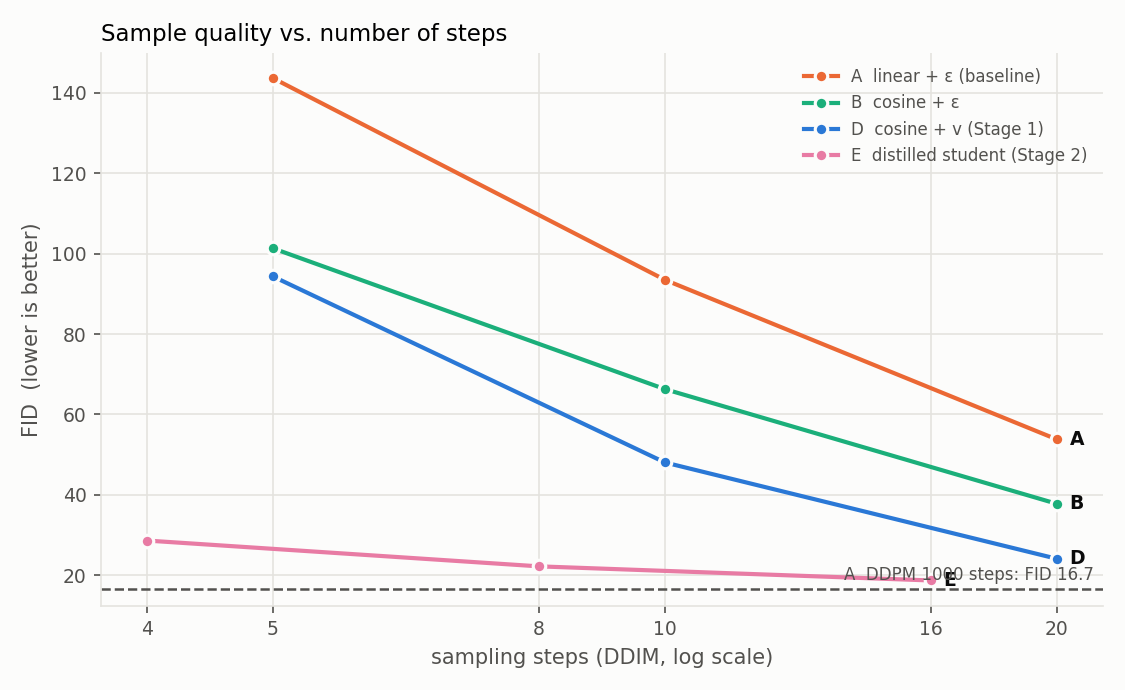

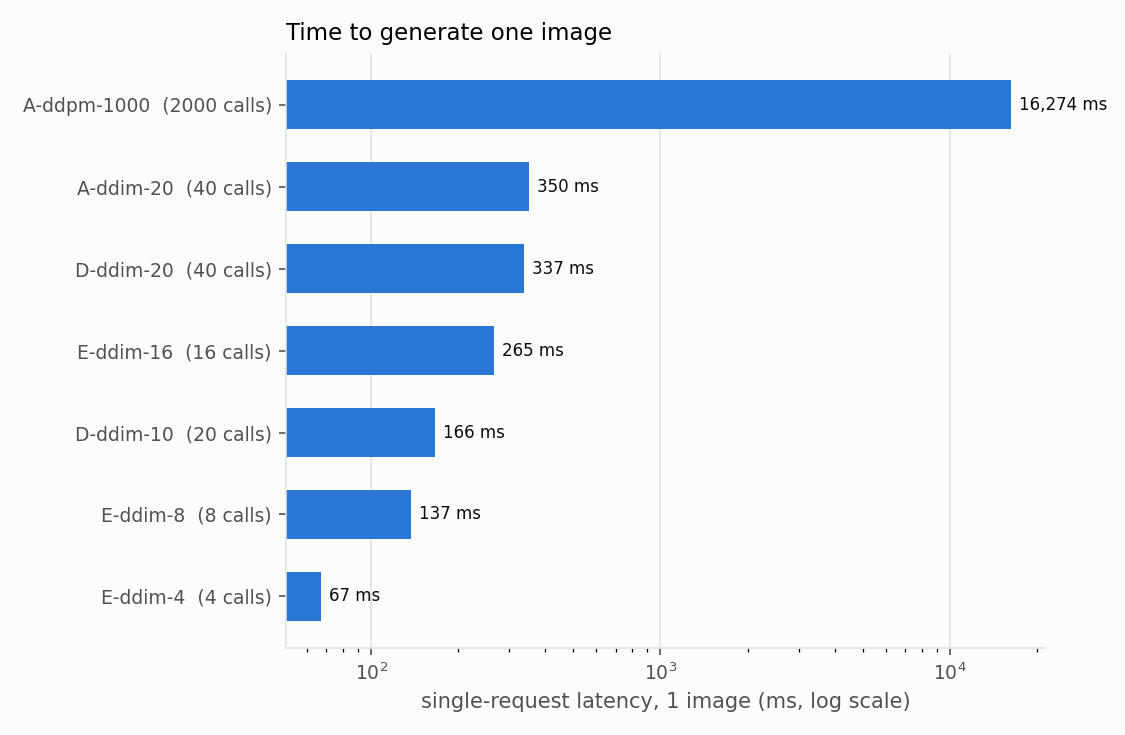

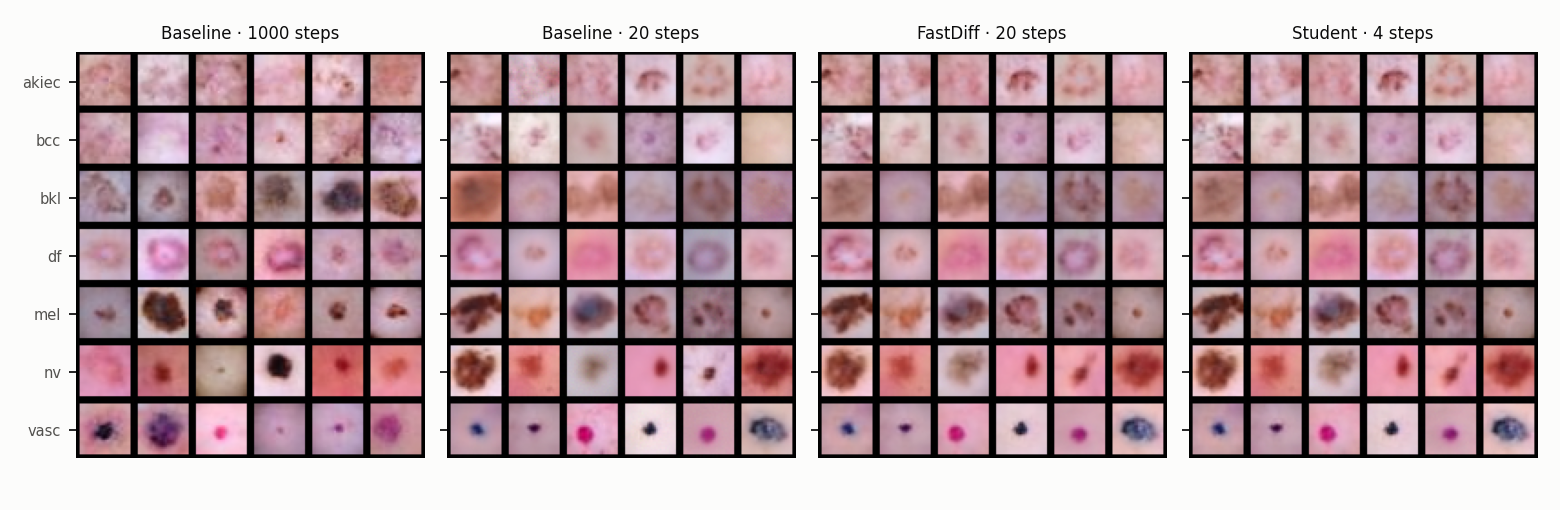

In [9]:
import pandas as pd
bench = pd.read_csv(f'{RESULTS}/benchmark.csv')
display(bench[['name', 'schedule', 'pred', 'sampler', 'steps', 'nfe', 'fid', 'class_acc', 'ms_per_image', 'single_latency_ms']].round(3))
show(f'{RESULTS}/fid_vs_steps.png', 750)
show(f'{RESULTS}/latency.png', 750)
show(f'{RESULTS}/sample_grid_compare.png', 900)

## 3. Real-world impact: synthetic augmentation of rare lesions
Every class except the largest is topped up to the size of the second-largest class (by default with
the 4-step student). A ResNet-18 is trained with 3 seeds on each arm and evaluated on the official
test split. We also time how long the synthetic set takes with the student compared with the
1000-step baseline; the baseline time is extrapolated from a subset.

In [10]:
if QUICK:
    !python -m src.augment_experiment --ckpt_dir {CKPT} --results_dir {RESULTS} --docs_dir {DOCS} --epochs 2 --seeds 0 --baseline_time_n 8
elif LITE:
    !python -m src.augment_experiment --ckpt_dir {CKPT} --results_dir {RESULTS} --docs_dir {DOCS} --epochs 20 --seeds 0 1 2 --baseline_time_n 100
else:
    !python -m src.augment_experiment --ckpt_dir {CKPT} --results_dir {RESULTS} --docs_dir {DOCS} --epochs 30 --seeds 0 1 2 --baseline_time_n 250


=== setting 100%: 7007 real images, counts {'akiec': np.int64(228), 'bcc': np.int64(359), 'bkl': np.int64(769), 'df': np.int64(80), 'mel': np.int64(779), 'nv': np.int64(4693), 'vasc': np.int64(99)}, top-up target 779, synthetic needed 2360
  generated 2360 synthetic images with Student-4 in 8.2s
  baseline DDPM-1000: 164.0s for 100 images -> ~3870s for the full set
  [100% | real | seed 0] training on 7007 images
    bal-acc 0.599  macro-F1 0.592
  [100% | real+oversample | seed 0] training on 9367 images
    bal-acc 0.516  macro-F1 0.539
  [100% | real+synthetic | seed 0] training on 9367 images
    bal-acc 0.591  macro-F1 0.586
  [100% | real | seed 1] training on 7007 images
    bal-acc 0.544  macro-F1 0.550
  [100% | real+oversample | seed 1] training on 9367 images
    bal-acc 0.548  macro-F1 0.553
  [100% | real+synthetic | seed 1] training on 9367 images
    bal-acc 0.583  macro-F1 0.560
  [100% | real | seed 2] training on 7007 images
    bal-acc 0.564  macro-F1 0.552
  [100% 

,setting,arm,n_train,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std
0,100%,real,7007,0.569,0.028,0.564,0.024
1,100%,real+oversample,9367,0.550,0.035,0.535,0.021
2,100%,real+synthetic,9367,0.587,0.004,0.563,0.021
3,20%,real,1403,0.429,0.019,0.427,0.040
4,20%,real+oversample,1875,0.430,0.017,0.388,0.040
5,20%,real+synthetic,1875,0.506,0.036,0.471,0.050


,setting,engine,n_images,measured_images,seconds,extrapolated
0,100%,Student-4,2360,2360,8.2,False
1,100%,Baseline-1000 (DDPM),2360,100,3869.6,True
2,20%,Student-4,472,472,1.5,False
3,20%,Baseline-1000 (DDPM),472,100,772.9,True


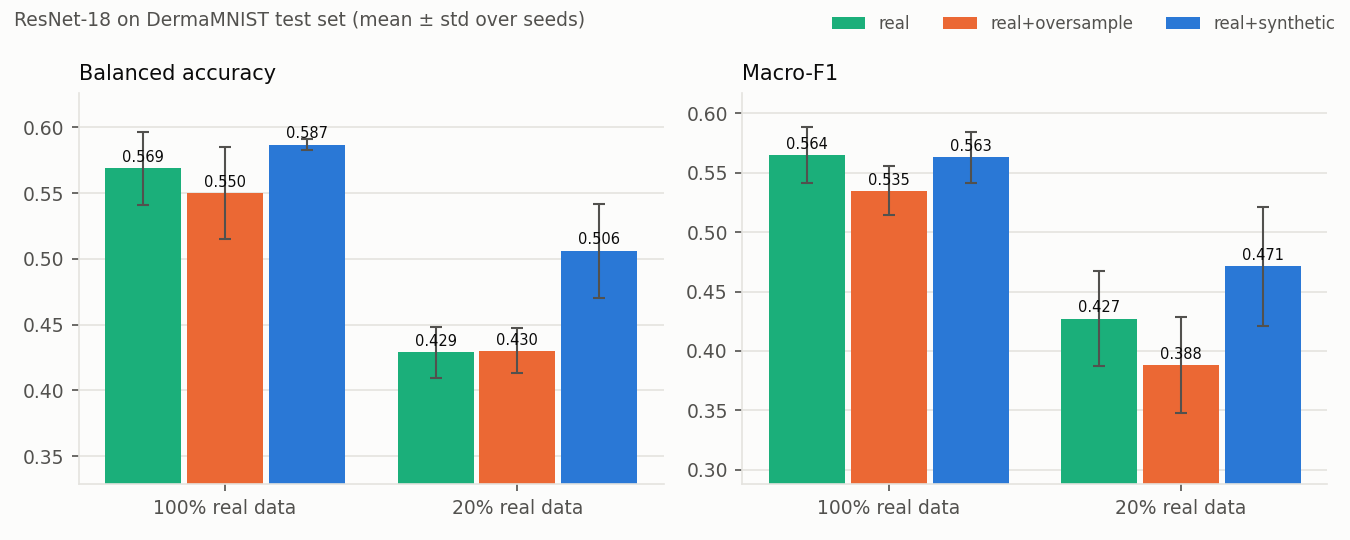

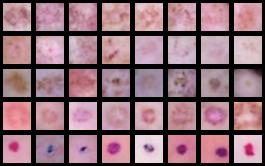

In [11]:
summ = pd.read_csv(f'{RESULTS}/augmentation_summary.csv')
display(summ[['setting', 'arm', 'n_train', 'balanced_accuracy_mean', 'balanced_accuracy_std', 'macro_f1_mean', 'macro_f1_std']].round(3))
display(pd.read_csv(f'{RESULTS}/gen_time.csv').round(1))
show(f'{RESULTS}/augmentation.png', 900)
show(f'{RESULTS}/grids/augment_synthetic.png', 400)

## 4. Results report
`docs/phase3_results.md` (on Drive) is regenerated from the CSVs. To publish, copy
`MyDrive/fastdiff-med/results/` into the repo's `results/` folder and the report into `docs/`.

In [12]:
!python -m src.report --results_dir {RESULTS} --docs_dir {DOCS}
from IPython.display import Markdown
display(Markdown(open(f'{DOCS}/phase3_results.md', encoding='utf-8').read().split('## Benchmark')[0]))

wrote /kaggle/working/fastdiff-med/docs/phase3_results.md


# Phase 3 — Results (auto-generated)

_Generated by `src/evaluate.py` / `src/augment_experiment.py` via `src/report.py`. Re-run those scripts to refresh._

## Headline

* **4 steps vs 1000 · 500× fewer network calls · FID 28.7 (student) vs 16.7 (baseline DDPM) · 243× lower single-image latency**
* Augmentation with 100% real data: macro-F1 -0.2 pts (0.565 → 0.563).
* Augmentation with 20% real data: macro-F1 +4.4 pts (0.427 → 0.471).
* Synthetic set (2360 images): 8.2 s with Student-4 vs ~64.5 min with the 1000-step baseline (extrapolated).



## Package everything for download
`fastdiff_outputs.zip` contains `results/` (CSVs, charts, grids), `docs/phase3_results.md`, the distilled
students, the judge and the training loss logs.

In [13]:
import zipfile
out = '/kaggle/working/fastdiff_outputs.zip' if IN_KAGGLE else f'{BASE}/fastdiff_outputs.zip'
with zipfile.ZipFile(out, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder, arc in [(RESULTS, 'results'), (DOCS, 'docs')]:
        for f in glob.glob(f'{folder}/**/*', recursive=True):
            if os.path.isfile(f):
                z.write(f, f'{arc}/{os.path.relpath(f, folder)}')
    for f in glob.glob(f'{CKPT}/distill/*') + glob.glob(f'{CKPT}/*/loss.csv') + [f'{CKPT}/judge.pt']:
        if os.path.isfile(f):
            z.write(f, f'checkpoints/{os.path.relpath(f, CKPT)}')
print(f'wrote {out}: {os.path.getsize(out) / 1e6:.0f} MB')

wrote /kaggle/working/fastdiff_outputs.zip: 226 MB
